# Task 2 — Complete Pipeline: Sentiment Analysis on IMDB 50K Movie Reviews

**One notebook, start to finish:**
1. **Part A — Dataset, Cleaning & EDA** (Task 2.1): load data, clean text, explore class balance/length/vocabulary, split train/test, build TF-IDF features
2. **Part B — Model Building** (Task 2.2): Naive Bayes, Logistic Regression, tuned Linear SVM, tuned Random Forest, Bidirectional LSTM
3. **Part C — Final Comparison** (Task 2.3): all five models compared side by side

**Before running:** download `IMDB Dataset.csv` from [Kaggle](https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews) and place it in the same folder as this notebook.

**Required packages:**
```
pip install pandas numpy matplotlib seaborn wordcloud nltk scikit-learn joblib tensorflow
```

Run all cells top to bottom — later sections use variables created earlier (e.g. `X_train_tfidf`, `y_train`), so nothing needs to be reloaded from disk unless you're resuming a partial run.

---


# Part A — Dataset, Cleaning & Exploratory Data Analysis

In [2]:
# --- Install any missing packages (run once) ---
# !pip install wordcloud nltk scikit-learn --quiet


In [3]:
import pandas as pd
import numpy as np
import re
import string
from collections import Counter

import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

import nltk
from nltk.corpus import stopwords
from nltk.util import ngrams

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

nltk.download('stopwords', quiet=True)
sns.set_style('whitegrid')


## 1. Load and Inspect the Data

In [4]:
df = pd.read_csv('IMDB Dataset.csv')

print("Shape:", df.shape)
print("\nColumn dtypes:\n", df.dtypes)
print("\nMissing values:\n", df.isnull().sum())
df.head()


Shape: (50000, 2)

Column dtypes:
 review       object
sentiment    object
dtype: object

Missing values:
 review       0
sentiment    0
dtype: int64


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


## 2. Class Balance

sentiment
positive    25000
negative    25000
Name: count, dtype: int64


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_41276\3167279157.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='sentiment', data=df, palette='Set2')


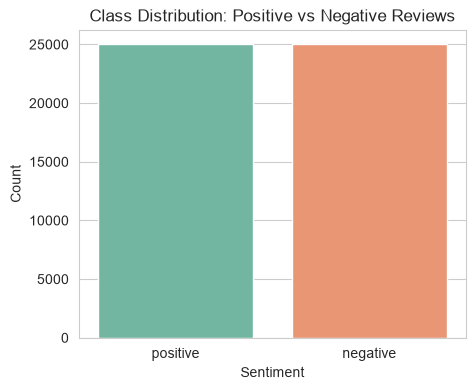

In [5]:
print(df['sentiment'].value_counts())

plt.figure(figsize=(5, 4))
sns.countplot(x='sentiment', data=df, palette='Set2')
plt.title('Class Distribution: Positive vs Negative Reviews')
plt.xlabel('Sentiment')
plt.ylabel('Count')
plt.show()


## 3. Review Length Distribution

count    50000.000000
mean       231.156940
std        171.343997
min          4.000000
25%        126.000000
50%        173.000000
75%        280.000000
max       2470.000000
Name: word_count, dtype: float64


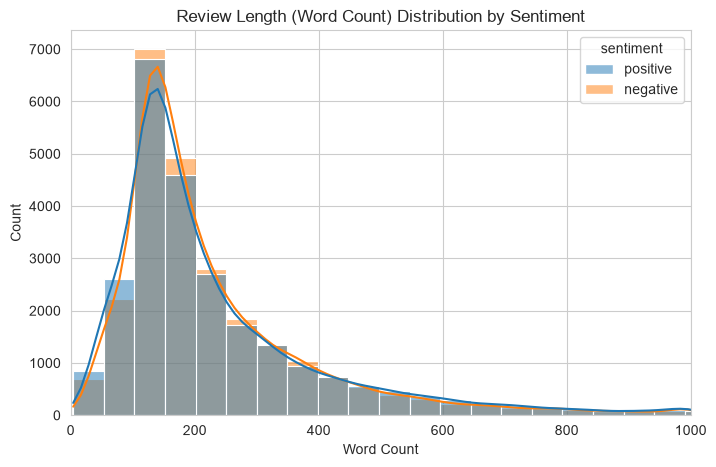

In [6]:
df['word_count'] = df['review'].apply(lambda x: len(x.split()))

print(df['word_count'].describe())

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='word_count', hue='sentiment', bins=50, kde=True, alpha=0.5)
plt.title('Review Length (Word Count) Distribution by Sentiment')
plt.xlabel('Word Count')
plt.xlim(0, 1000)
plt.show()


## 4. Text Cleaning

Raw reviews contain HTML line-break tags (`<br />`), punctuation, and mixed casing.
The cleaning function below:
- strips HTML tags
- lowercases text
- removes punctuation and non-alphabetic characters
- removes stopwords


In [7]:
stop_words = set(stopwords.words('english'))

def clean_text(text):
    text = re.sub(r'<.*?>', ' ', text)                     # remove HTML tags
    text = text.lower()                                     # lowercase
    text = re.sub(r'[^a-z\s]', ' ', text)                    # remove punctuation/digits
    text = re.sub(r'\s+', ' ', text).strip()                 # collapse whitespace
    tokens = [w for w in text.split() if w not in stop_words and len(w) > 1]
    return ' '.join(tokens)

df['clean_review'] = df['review'].apply(clean_text)
df[['review', 'clean_review']].head(3)


,review,clean_review
0,One of the other reviewers has mentioned that ...,one reviewers mentioned watching oz episode ho...
1,A wonderful little production. <br /><br />The...,wonderful little production filming technique ...
2,I thought this was a wonderful way to spend ti...,thought wonderful way spend time hot summer we...


## 5. Most Frequent Words per Class

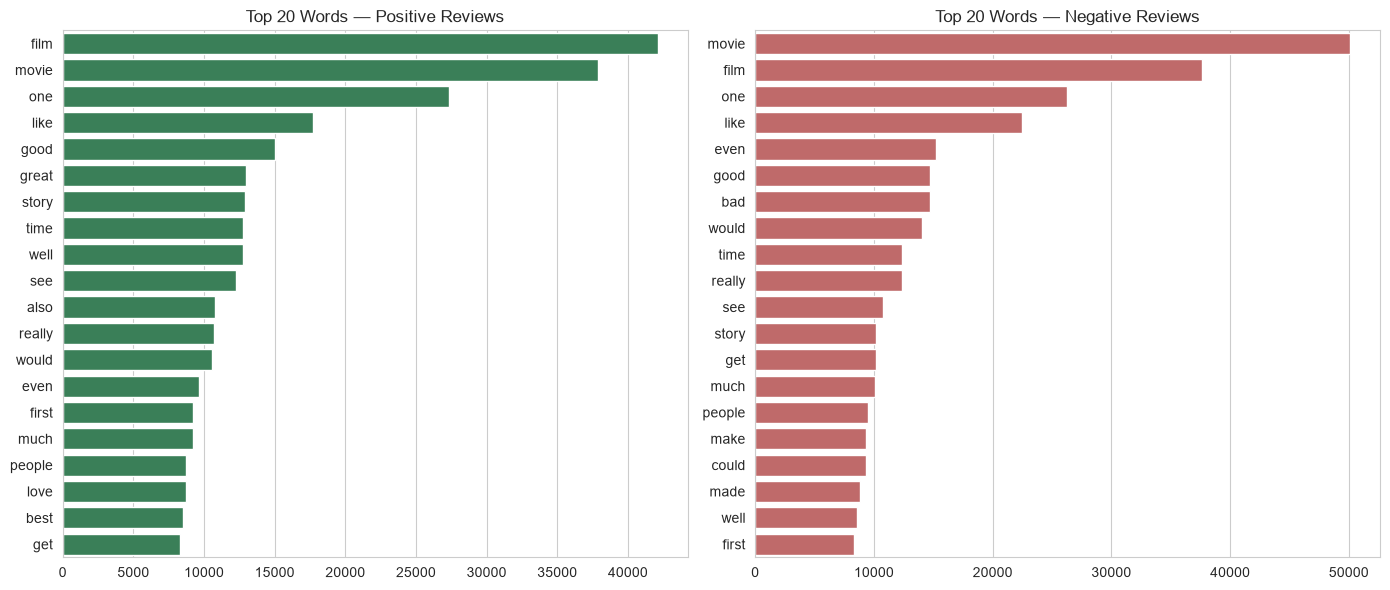

In [8]:
def top_words(sentiment_label, n=20):
    text = ' '.join(df[df['sentiment'] == sentiment_label]['clean_review'])
    counts = Counter(text.split())
    return counts.most_common(n)

pos_top = top_words('positive')
neg_top = top_words('negative')

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(x=[c for _, c in pos_top], y=[w for w, _ in pos_top], ax=axes[0], color='seagreen')
axes[0].set_title('Top 20 Words — Positive Reviews')
sns.barplot(x=[c for _, c in neg_top], y=[w for w, _ in neg_top], ax=axes[1], color='indianred')
axes[1].set_title('Top 20 Words — Negative Reviews')
plt.tight_layout()
plt.show()


## 6. Bigram Analysis

In [9]:
def top_bigrams(sentiment_label, n=15):
    text = ' '.join(df[df['sentiment'] == sentiment_label]['clean_review']).split()
    bigrams = list(ngrams(text, 2))
    counts = Counter(bigrams)
    return counts.most_common(n)

print("Top bigrams — Positive:")
for bg, c in top_bigrams('positive'):
    print(f"  {' '.join(bg):<25} {c}")

print("\nTop bigrams — Negative:")
for bg, c in top_bigrams('negative'):
    print(f"  {' '.join(bg):<25} {c}")


Top bigrams — Positive:
  one best                  1680
  even though               1099
  ever seen                 977
  first time                960
  new york                  855
  special effects           806
  see movie                 784
  must see                  778
  real life                 761
  years ago                 741
  good movie                735
  well done                 727
  great movie               702
  year old                  686
  sci fi                    623

Top bigrams — Negative:
  ever seen                 1734
  special effects           1443
  waste time                1437
  looks like                1235
  low budget                1229
  much better               1009
  one worst                 964
  look like                 945
  bad movie                 926
  year old                  915
  even though               900
  movie ever                872
  sci fi                    770
  watch movie               766
  see movie    

## 7. Word Clouds

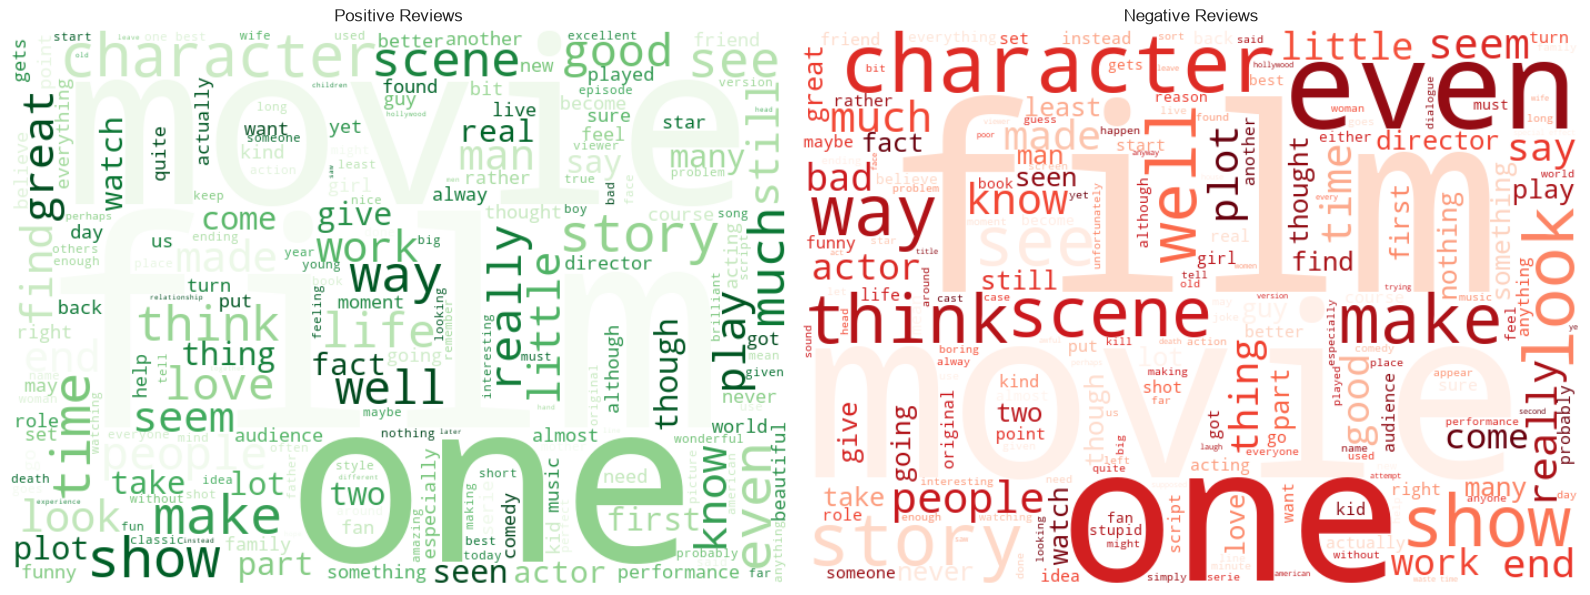

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

pos_text = ' '.join(df[df['sentiment'] == 'positive']['clean_review'])
neg_text = ' '.join(df[df['sentiment'] == 'negative']['clean_review'])

wc_pos = WordCloud(width=700, height=500, background_color='white', colormap='Greens').generate(pos_text)
wc_neg = WordCloud(width=700, height=500, background_color='white', colormap='Reds').generate(neg_text)

axes[0].imshow(wc_pos, interpolation='bilinear')
axes[0].set_title('Positive Reviews')
axes[0].axis('off')

axes[1].imshow(wc_neg, interpolation='bilinear')
axes[1].set_title('Negative Reviews')
axes[1].axis('off')

plt.tight_layout()
plt.show()


## 8. Train/Test Split + TF-IDF Vectorization

This prepares the data for Task 2.2 (each member can load `X_train_tfidf`, `X_test_tfidf`,
`y_train`, `y_test` for their assigned model — Naive Bayes/Logistic Regression, SVM/Random Forest,
and LSTM/DistilBERT respectively; the deep learning model will instead need a Keras/HF tokenizer
rather than TF-IDF, but the same train/test split of `clean_review` and `sentiment` applies).


In [11]:
df['label'] = df['sentiment'].map({'positive': 1, 'negative': 0})

X_train, X_test, y_train, y_test = train_test_split(
    df['clean_review'], df['label'], test_size=0.2, random_state=42, stratify=df['label']
)

print("Train size:", X_train.shape[0], "| Test size:", X_test.shape[0])

tfidf = TfidfVectorizer(max_features=10000, ngram_range=(1, 2))
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF matrix shape (train):", X_train_tfidf.shape)


Train size: 40000 | Test size: 10000
TF-IDF matrix shape (train): (40000, 10000)


In [12]:
# Save processed splits for the modeling notebooks (Task 2.2)
import scipy.sparse as sp
import joblib

sp.save_npz('X_train_tfidf.npz', X_train_tfidf)
sp.save_npz('X_test_tfidf.npz', X_test_tfidf)
y_train.to_csv('y_train.csv', index=False)
y_test.to_csv('y_test.csv', index=False)
joblib.dump(tfidf, 'tfidf_vectorizer.pkl')

# Also save the cleaned text splits (needed for the deep learning model's own tokenizer)
X_train.to_csv('X_train_text.csv', index=False)
X_test.to_csv('X_test_text.csv', index=False)

print("Saved: X_train_tfidf.npz, X_test_tfidf.npz, y_train.csv, y_test.csv, tfidf_vectorizer.pkl, X_train_text.csv, X_test_text.csv")


Saved: X_train_tfidf.npz, X_test_tfidf.npz, y_train.csv, y_test.csv, tfidf_vectorizer.pkl, X_train_text.csv, X_test_text.csv


---
# Part B & C — Model Building, Tuning & Final Comparison

## Part 1 — Baseline: Naive Bayes & Logistic Regression

In [13]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, classification_report, confusion_matrix)

sns.set_style('whitegrid')


## 1. Load Preprocessed Data

In [14]:
X_train = sp.load_npz('X_train_tfidf.npz')
X_test = sp.load_npz('X_test_tfidf.npz')
y_train = pd.read_csv('y_train.csv').values.ravel()
y_test = pd.read_csv('y_test.csv').values.ravel()

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)


X_train: (40000, 10000) | X_test: (10000, 10000)
y_train: (40000,) | y_test: (10000,)


## 2. Model A — Multinomial Naive Bayes

In [15]:
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)
nb_preds = nb_model.predict(X_test)

nb_metrics = {
    'accuracy': accuracy_score(y_test, nb_preds),
    'precision': precision_score(y_test, nb_preds),
    'recall': recall_score(y_test, nb_preds),
    'f1': f1_score(y_test, nb_preds)
}
print("Naive Bayes Results:")
for k, v in nb_metrics.items():
    print(f"  {k}: {v:.4f}")
print("\n", classification_report(y_test, nb_preds, target_names=['negative', 'positive']))


Naive Bayes Results:
  accuracy: 0.8669
  precision: 0.8555
  recall: 0.8830
  f1: 0.8690

               precision    recall  f1-score   support

    negative       0.88      0.85      0.86      5000
    positive       0.86      0.88      0.87      5000

    accuracy                           0.87     10000
   macro avg       0.87      0.87      0.87     10000
weighted avg       0.87      0.87      0.87     10000



## 3. Model B — Logistic Regression

In [16]:
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)
lr_preds = lr_model.predict(X_test)

lr_metrics = {
    'accuracy': accuracy_score(y_test, lr_preds),
    'precision': precision_score(y_test, lr_preds),
    'recall': recall_score(y_test, lr_preds),
    'f1': f1_score(y_test, lr_preds)
}
print("Logistic Regression Results:")
for k, v in lr_metrics.items():
    print(f"  {k}: {v:.4f}")
print("\n", classification_report(y_test, lr_preds, target_names=['negative', 'positive']))


Logistic Regression Results:
  accuracy: 0.8986
  precision: 0.8925
  recall: 0.9064
  f1: 0.8994

               precision    recall  f1-score   support

    negative       0.90      0.89      0.90      5000
    positive       0.89      0.91      0.90      5000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



## 4. Compare Baselines

                     accuracy  precision  recall        f1
Naive Bayes            0.8669   0.855454  0.8830  0.869009
Logistic Regression    0.8986   0.892477  0.9064  0.899385


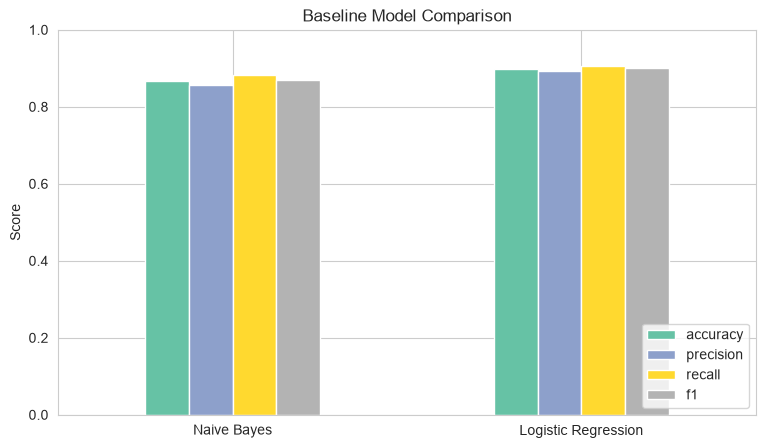

In [17]:
results_df = pd.DataFrame([nb_metrics, lr_metrics], index=['Naive Bayes', 'Logistic Regression'])
print(results_df)

results_df.plot(kind='bar', figsize=(9, 5), colormap='Set2')
plt.title('Baseline Model Comparison')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()


## 5. Confusion Matrices

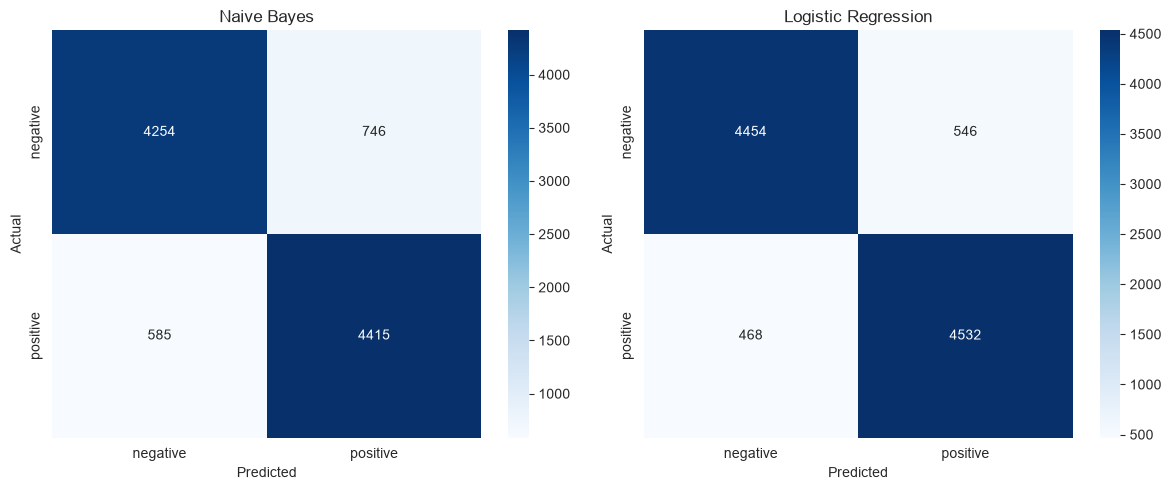

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, preds, title in zip(axes, [nb_preds, lr_preds], ['Naive Bayes', 'Logistic Regression']):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['negative', 'positive'], yticklabels=['negative', 'positive'])
    ax.set_title(title)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()


## 6. Save Best Baseline Model

In [19]:
import joblib

# Pick whichever performed better based on the metrics above
best_model = lr_model if lr_metrics['f1'] >= nb_metrics['f1'] else nb_model
best_name = 'logistic_regression' if lr_metrics['f1'] >= nb_metrics['f1'] else 'naive_bayes'

joblib.dump(best_model, f'model_baseline_{best_name}.pkl')
print(f"Saved best baseline model as: model_baseline_{best_name}.pkl")


Saved best baseline model as: model_baseline_logistic_regression.pkl


---
## Part 2 — Classical (Tuned): Linear SVM & Random Forest

In [20]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, classification_report, confusion_matrix)

sns.set_style('whitegrid')


## 1. Load Preprocessed Data

In [21]:
X_train = sp.load_npz('X_train_tfidf.npz')
X_test = sp.load_npz('X_test_tfidf.npz')
y_train = pd.read_csv('y_train.csv').values.ravel()
y_test = pd.read_csv('y_test.csv').values.ravel()

print("X_train:", X_train.shape, "| X_test:", X_test.shape)


X_train: (40000, 10000) | X_test: (10000, 10000)


## 2. Model A — Linear SVM (with GridSearchCV tuning)

Tuning the `C` (regularization strength) parameter — smaller values = stronger regularization.


In [22]:
svm_param_grid = {'C': [0.01, 0.1, 1, 10]}

svm_grid = GridSearchCV(LinearSVC(max_iter=5000, random_state=42),
                         svm_param_grid, cv=3, scoring='f1', n_jobs=-1, verbose=1)

start = time.time()
svm_grid.fit(X_train, y_train)
print(f"Tuning took {time.time() - start:.1f}s")

print("Best params:", svm_grid.best_params_)
print("Best CV F1 score:", svm_grid.best_score_)

svm_best = svm_grid.best_estimator_
svm_preds = svm_best.predict(X_test)


Fitting 3 folds for each of 4 candidates, totalling 12 fits
Tuning took 21.7s
Best params: {'C': 0.1}
Best CV F1 score: 0.89349615525354


In [23]:
svm_metrics = {
    'accuracy': accuracy_score(y_test, svm_preds),
    'precision': precision_score(y_test, svm_preds),
    'recall': recall_score(y_test, svm_preds),
    'f1': f1_score(y_test, svm_preds)
}
print("Tuned SVM Test Results:")
for k, v in svm_metrics.items():
    print(f"  {k}: {v:.4f}")
print("\n", classification_report(y_test, svm_preds, target_names=['negative', 'positive']))


Tuned SVM Test Results:
  accuracy: 0.8990
  precision: 0.8918
  recall: 0.9082
  f1: 0.8999

               precision    recall  f1-score   support

    negative       0.91      0.89      0.90      5000
    positive       0.89      0.91      0.90      5000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



## 3. Model B — Random Forest (with RandomizedSearchCV tuning)

Uses random search instead of exhaustive grid search since Random Forest on 10,000 TF-IDF features
is expensive to tune exhaustively.


In [24]:
rf_param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 20, 40],
    'min_samples_split': [2, 5, 10]
}

rf_search = RandomizedSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1),
                                rf_param_dist, n_iter=6, cv=3, scoring='f1',
                                random_state=42, n_jobs=-1, verbose=1)

start = time.time()
rf_search.fit(X_train, y_train)
print(f"Tuning took {time.time() - start:.1f}s")

print("Best params:", rf_search.best_params_)
print("Best CV F1 score:", rf_search.best_score_)

rf_best = rf_search.best_estimator_
rf_preds = rf_best.predict(X_test)


Fitting 3 folds for each of 6 candidates, totalling 18 fits
Tuning took 409.3s
Best params: {'n_estimators': 300, 'min_samples_split': 10, 'max_depth': None}
Best CV F1 score: 0.8585636189834601


In [25]:
rf_metrics = {
    'accuracy': accuracy_score(y_test, rf_preds),
    'precision': precision_score(y_test, rf_preds),
    'recall': recall_score(y_test, rf_preds),
    'f1': f1_score(y_test, rf_preds)
}
print("Tuned Random Forest Test Results:")
for k, v in rf_metrics.items():
    print(f"  {k}: {v:.4f}")
print("\n", classification_report(y_test, rf_preds, target_names=['negative', 'positive']))


Tuned Random Forest Test Results:
  accuracy: 0.8649
  precision: 0.8685
  recall: 0.8600
  f1: 0.8642

               precision    recall  f1-score   support

    negative       0.86      0.87      0.87      5000
    positive       0.87      0.86      0.86      5000

    accuracy                           0.86     10000
   macro avg       0.86      0.86      0.86     10000
weighted avg       0.86      0.86      0.86     10000



## 4. Compare SVM vs Random Forest

                       accuracy  precision  recall        f1
SVM (tuned)              0.8990   0.891791  0.9082  0.899921
Random Forest (tuned)    0.8649   0.868511  0.8600  0.864235


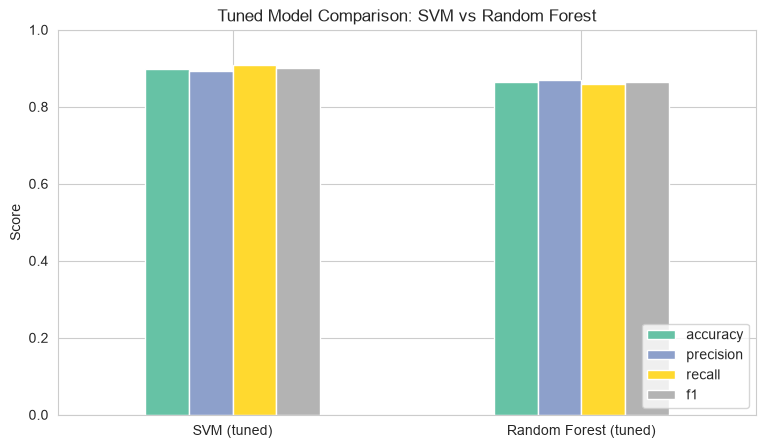

In [26]:
results_df = pd.DataFrame([svm_metrics, rf_metrics], index=['SVM (tuned)', 'Random Forest (tuned)'])
print(results_df)

results_df.plot(kind='bar', figsize=(9, 5), colormap='Set2')
plt.title('Tuned Model Comparison: SVM vs Random Forest')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()


## 5. Confusion Matrices

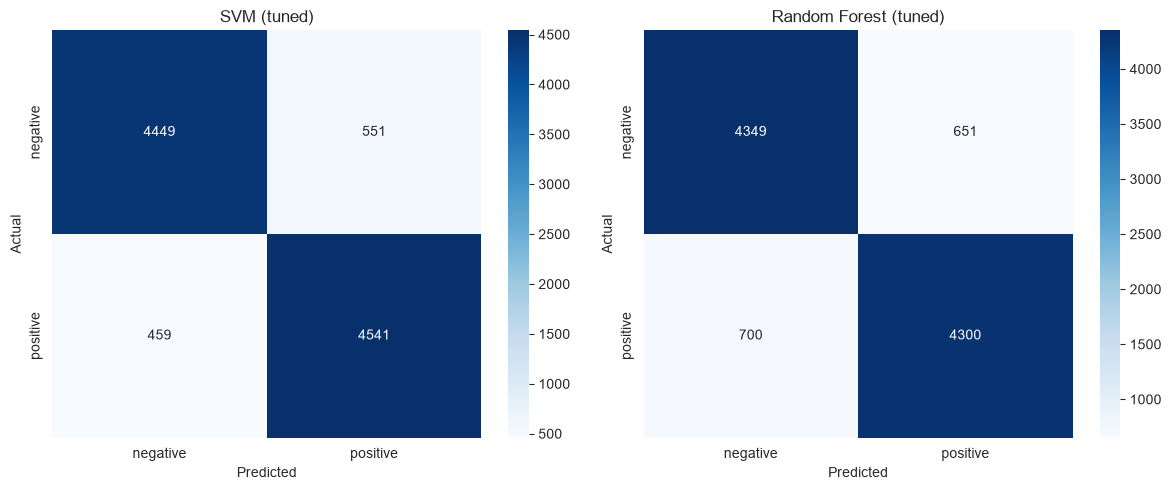

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, preds, title in zip(axes, [svm_preds, rf_preds], ['SVM (tuned)', 'Random Forest (tuned)']):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['negative', 'positive'], yticklabels=['negative', 'positive'])
    ax.set_title(title)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()


## 6. Save Best Model

In [28]:
import joblib

best_model = svm_best if svm_metrics['f1'] >= rf_metrics['f1'] else rf_best
best_name = 'svm' if svm_metrics['f1'] >= rf_metrics['f1'] else 'random_forest'

joblib.dump(best_model, f'model_classical_{best_name}.pkl')
print(f"Saved best classical model as: model_classical_{best_name}.pkl")


Saved best classical model as: model_classical_svm.pkl


---
## Part 3 — Deep Learning: Bidirectional LSTM

In [29]:
# !pip install tensorflow --quiet


In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, classification_report, confusion_matrix)
import seaborn as sns

sns.set_style('whitegrid')
tf.random.set_seed(42)


## 1. Load Cleaned Text Data

In [31]:
X_train_text = pd.read_csv('X_train_text.csv').iloc[:, 0].astype(str)
X_test_text = pd.read_csv('X_test_text.csv').iloc[:, 0].astype(str)
y_train = pd.read_csv('y_train.csv').values.ravel()
y_test = pd.read_csv('y_test.csv').values.ravel()

print("Train:", X_train_text.shape, "| Test:", X_test_text.shape)


Train: (40000,) | Test: (10000,)


## 2. Tokenize and Pad Sequences

In [32]:
VOCAB_SIZE = 15000
MAX_LEN = 200          # truncate/pad reviews to 200 tokens
EMBED_DIM = 100
LSTM_UNITS = 64

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train_text)

X_train_seq = tokenizer.texts_to_sequences(X_train_text)
X_test_seq = tokenizer.texts_to_sequences(X_test_text)

X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_LEN, padding='post', truncating='post')
X_test_pad = pad_sequences(X_test_seq, maxlen=MAX_LEN, padding='post', truncating='post')

print("Padded train shape:", X_train_pad.shape)
print("Padded test shape:", X_test_pad.shape)


Padded train shape: (40000, 200)
Padded test shape: (10000, 200)


## 3. Build the Bidirectional LSTM Model

In [33]:
model = Sequential([
    Embedding(input_dim=VOCAB_SIZE, output_dim=EMBED_DIM, input_length=MAX_LEN),
    Bidirectional(LSTM(LSTM_UNITS, return_sequences=False)),
    Dropout(0.5),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()


c:\Users\Lenovo\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## 4. Train the Model

In [34]:
early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)

history = model.fit(
    X_train_pad, y_train,
    validation_split=0.1,
    epochs=10,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/10
563/563 ━━━━━━━━━━━━━━━━━━━━ 189s 314ms/step - accuracy: 0.8193 - loss: 0.3937 - val_accuracy: 0.8913 - val_loss: 0.2770
Epoch 2/10
563/563 ━━━━━━━━━━━━━━━━━━━━ 191s 295ms/step - accuracy: 0.9190 - loss: 0.2215 - val_accuracy: 0.8878 - val_loss: 0.3035
Epoch 3/10
563/563 ━━━━━━━━━━━━━━━━━━━━ 205s 301ms/step - accuracy: 0.9409 - loss: 0.1672 - val_accuracy: 0.8450 - val_loss: 0.4256


## 5. Training Curves

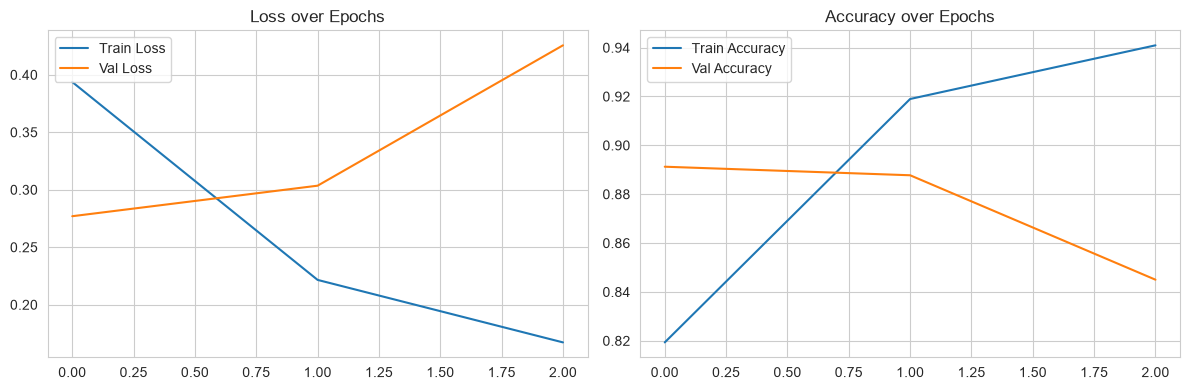

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history['loss'], label='Train Loss')
axes[0].plot(history.history['val_loss'], label='Val Loss')
axes[0].set_title('Loss over Epochs')
axes[0].legend()

axes[1].plot(history.history['accuracy'], label='Train Accuracy')
axes[1].plot(history.history['val_accuracy'], label='Val Accuracy')
axes[1].set_title('Accuracy over Epochs')
axes[1].legend()

plt.tight_layout()
plt.show()


## 6. Evaluate on Test Set

In [36]:
lstm_probs = model.predict(X_test_pad)
lstm_preds = (lstm_probs > 0.5).astype(int).ravel()

lstm_metrics = {
    'accuracy': accuracy_score(y_test, lstm_preds),
    'precision': precision_score(y_test, lstm_preds),
    'recall': recall_score(y_test, lstm_preds),
    'f1': f1_score(y_test, lstm_preds)
}
print("LSTM Test Results:")
for k, v in lstm_metrics.items():
    print(f"  {k}: {v:.4f}")
print("\n", classification_report(y_test, lstm_preds, target_names=['negative', 'positive']))


313/313 ━━━━━━━━━━━━━━━━━━━━ 18s 55ms/step
LSTM Test Results:
  accuracy: 0.8872
  precision: 0.8897
  recall: 0.8840
  f1: 0.8868

               precision    recall  f1-score   support

    negative       0.88      0.89      0.89      5000
    positive       0.89      0.88      0.89      5000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



## 7. Confusion Matrix

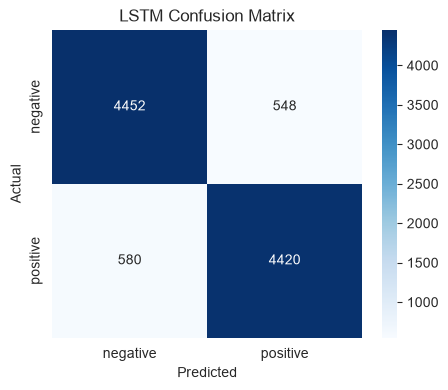

In [37]:
cm = confusion_matrix(y_test, lstm_preds)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['negative', 'positive'], yticklabels=['negative', 'positive'])
plt.title('LSTM Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


## 8. Hyperparameter Tuning Notes (Task 2.3)

Deep learning models aren't tuned with `GridSearchCV` the way classical models are (too slow to retrain
a neural net dozens of times). Instead, document a **manual tuning log** for your report — retrain this
notebook a few times varying one thing at a time and record results here, e.g.:

| Run | LSTM_UNITS | EMBED_DIM | Dropout | Val Accuracy |
|---|---|---|---|---|
| 1 | 64 | 100 | 0.5 | ... |
| 2 | 128 | 100 | 0.5 | ... |
| 3 | 64 | 200 | 0.3 | ... |

Report the best configuration and compare it against your SVM/Random Forest tuning from Notebook 2.


## 9. Save the Model

In [38]:
import pickle

model.save('model_lstm.keras')

with open('tokenizer.pkl', 'wb') as f:
    pickle.dump(tokenizer, f)

print("Saved: model_lstm.keras, tokenizer.pkl")


Saved: model_lstm.keras, tokenizer.pkl


---
## Final Comparison — All Three Models

Run this after all three parts above have completed, to build one combined comparison table/plot for your report.


                       accuracy  precision  recall        f1
Naive Bayes              0.8669   0.855454  0.8830  0.869009
Logistic Regression      0.8986   0.892477  0.9064  0.899385
SVM (tuned)              0.8990   0.891791  0.9082  0.899921
Random Forest (tuned)    0.8649   0.868511  0.8600  0.864235
LSTM                     0.8872   0.889694  0.8840  0.886838


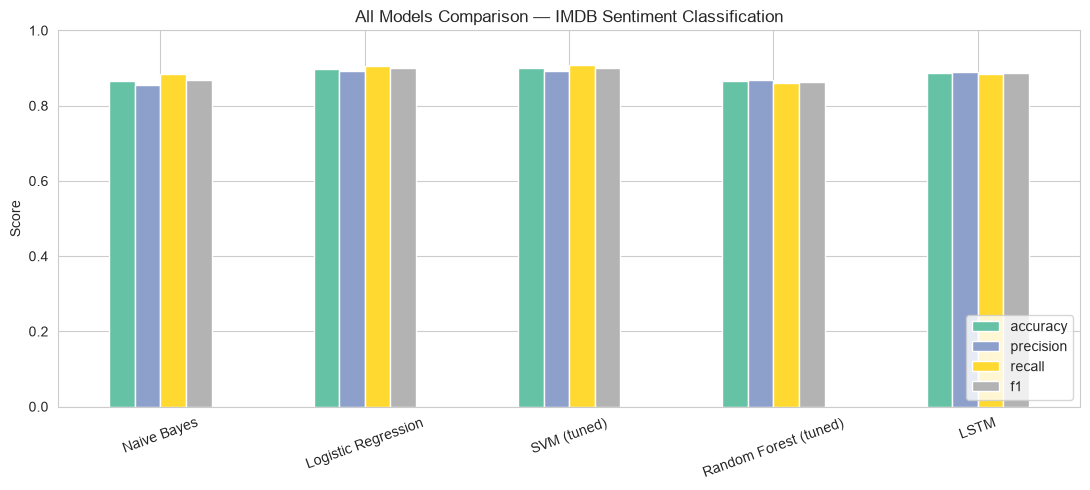


Best overall model by F1 score: SVM (tuned)


In [39]:
import pandas as pd
import matplotlib.pyplot as plt

all_results = pd.DataFrame([nb_metrics, lr_metrics, svm_metrics, rf_metrics, lstm_metrics],
                            index=['Naive Bayes', 'Logistic Regression', 'SVM (tuned)',
                                   'Random Forest (tuned)', 'LSTM'])
print(all_results)

all_results.plot(kind='bar', figsize=(11, 5), colormap='Set2')
plt.title('All Models Comparison — IMDB Sentiment Classification')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

best_overall = all_results['f1'].idxmax()
print(f"\nBest overall model by F1 score: {best_overall}")


---
# Part D — Deployment (Task 2.4)

The best-performing model above (tuned Linear SVM) and its TF-IDF vectorizer were saved to disk as
`model_classical_svm.pkl` and `tfidf_vectorizer.pkl` in the cells above. The cell below contains the
full Streamlit web app that loads those files and serves predictions on a live webpage.

**Running the cell below does NOT launch the webpage** — Streamlit apps run as their own process, not
inside a notebook cell. Instead, the `%%writefile` command saves the code as `app.py` in the same folder
as this notebook. After running the cell once, open a terminal in that folder and run:

```bash
pip install streamlit
streamlit run app.py
```

This opens a browser window where you can type a review and get a live positive/negative prediction
from the exact model trained above. Take a screenshot of it running for the report's deployment section.


In [40]:
%%writefile app.py
import streamlit as st
import joblib
import re
from nltk.corpus import stopwords
import nltk

# --- One-time setup ---
nltk.download('stopwords', quiet=True)
stop_words = set(stopwords.words('english'))

# --- Same cleaning function used during training (must match exactly) ---
def clean_text(text):
    text = re.sub(r'<.*?>', ' ', text)                     # remove HTML tags
    text = text.lower()                                     # lowercase
    text = re.sub(r'[^a-z\\s]', ' ', text)                    # remove punctuation/digits
    text = re.sub(r'\\s+', ' ', text).strip()                 # collapse whitespace
    tokens = [w for w in text.split() if w not in stop_words and len(w) > 1]
    return ' '.join(tokens)

# --- Load the trained model and vectorizer (cached so it only loads once) ---
@st.cache_resource
def load_model():
    model = joblib.load('model_classical_svm.pkl')
    vectorizer = joblib.load('tfidf_vectorizer.pkl')
    return model, vectorizer

model, tfidf = load_model()

# --- Page layout ---
st.set_page_config(page_title="Movie Review Sentiment Classifier", page_icon="\U0001F3AC")
st.title("\U0001F3AC Movie Review Sentiment Classifier")
st.write(
    "Enter a movie review below and the model will predict whether it\'s "
    "**positive** or **negative**. Powered by a tuned Linear SVM trained on "
    "the IMDB 50K Movie Reviews dataset (F1 = 0.8999)."
)

review_text = st.text_area("Your review:", height=150, placeholder="Type or paste a movie review here...")

if st.button("Predict Sentiment"):
    if not review_text.strip():
        st.warning("Please enter a review first.")
    else:
        cleaned = clean_text(review_text)
        features = tfidf.transform([cleaned])
        prediction = model.predict(features)[0]

        if prediction == 1:
            st.success("**Predicted sentiment: Positive** \U0001F60A")
        else:
            st.error("**Predicted sentiment: Negative** \U0001F61E")

        with st.expander("See cleaned text (what the model actually saw)"):
            st.write(cleaned if cleaned else "*(nothing left after cleaning)*")

st.markdown("---")
st.caption("CT052-3-M-NLP — Task 2: Text Classification (Sentiment Analysis)")


Overwriting app.py
